/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/bempp_cl/api/assembly/discrete_boundary_operator.py:619: SparseEfficiencyWarning: splu converted its input to CSC format
  solver = solver_interface(actual_mat)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/bempp_cl/api/assembly/discrete_boundary_operator.py:619: SparseEfficiencyWarning: splu converted its input to CSC format
  solver = solver_interface(actual_mat)


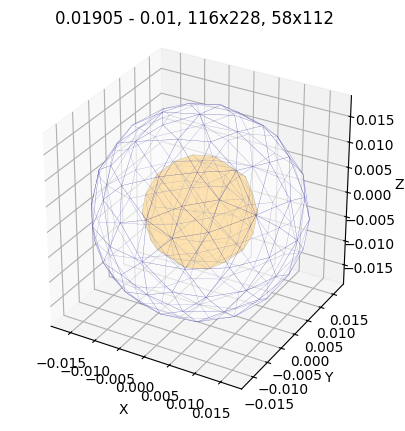

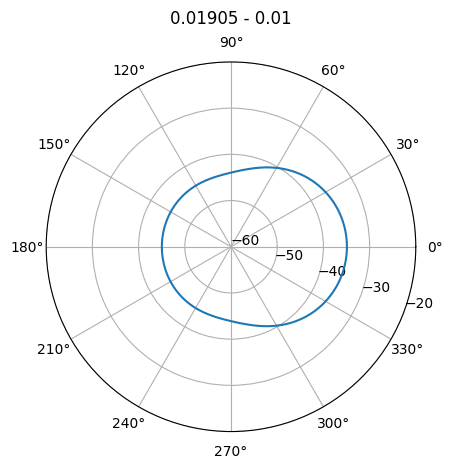

#deg	lbs
0	0.0179685
1	0.0179653
2	0.0179553
3	0.0179386
4	0.0179152
5	0.0178851
6	0.0178483
7	0.017805
8	0.0177551
9	0.0176987
10	0.0176359
11	0.0175668
12	0.0174914
13	0.0174099
14	0.0173224
15	0.0172289
16	0.0171296
17	0.0170246
18	0.016914
19	0.0167981
20	0.0166768
21	0.0165504
22	0.016419
23	0.0162828
24	0.016142
25	0.0159967
26	0.0158471
27	0.0156934
28	0.0155358
29	0.0153745
30	0.0152096
31	0.0150414
32	0.0148701
33	0.0146958
34	0.0145188
35	0.0143394
36	0.0141576
37	0.0139738
38	0.0137881
39	0.0136008
40	0.013412
41	0.0132221
42	0.0130312
43	0.0128395
44	0.0126474
45	0.0124549
46	0.0122623
47	0.0120698
48	0.0118778
49	0.0116862
50	0.0114955
51	0.0113058
52	0.0111173
53	0.0109302
54	0.0107447
55	0.010561
56	0.0103794
57	0.0102
58	0.0100229
59	0.00984852
60	0.00967685
61	0.00950811
62	0.00934248
63	0.00918011
64	0.00902115
65	0.00886575
66	0.00871403
67	0.00856613
68	0.00842217
69	0.00828225
70	0.00814646
71	0.00801491
72	0.00788765
73	0.00776476
74	0.00764628
75	0.00753225
76	0.

In [15]:
# !pip install --force-reinstall "numpy<=2.2" scipy bempp-cl matplotlib

# MM 18.7.2025: scattering from spheres - double transmission problem
import bempp_cl.api
from bempp_cl.api.operators.boundary import helmholtz, sparse
from bempp_cl.api.operators.potential import helmholtz as potential
from scipy.sparse.linalg import gmres
from numpy import pi,sin,cos,exp,log10,abs,array,linspace,block

# input parameters
f0, c0, rho0 = 38e3,    1480, 1024  # sea water
a1, c1, rho1 = 0.01905, 1540, 1045  # fluid bubble
a2, c2, rho2 = 0.01,     340, 1.29  # air bubble

fname="%g - %g"%(a1,a2)
# target mesh and its space
grid = bempp_cl.api.shapes.sphere(r=a1, h=c0/f0/5)  # generated mesh
grid2 = bempp_cl.api.shapes.sphere(r=a2, h=c0/f0/5) # generated mesh
#grid = bempp_cl.api.import_grid("sphere-1.905-600.msh")
#grid2 = bempp_cl.api.import_grid("sphere-1.0-300.msh")
Sp = bempp_cl.api.function_space(grid, "P", 1)
Sp2 = bempp_cl.api.function_space(grid2, "P", 1)
N, N2 = Sp.global_dof_count, Sp2.global_dof_count

# calculated values
k0, k1, k2 = 2*pi*f0/c0, 2*pi*f0/c1, 2*pi*f0/c2 # wave numbers
d = array([1.0, 0, 0])                  # plane wave direction
z = array([0]*N2)

# incident pressure and its normal derivative
@bempp_cl.api.complex_callable
def pinc(x, n, idx, res): res[0] = exp(1j*k0*d.dot(x))
f = bempp_cl.api.GridFunction(Sp, fun=pinc).coefficients
@bempp_cl.api.complex_callable
def dpinc(x, n, idx, res): res[0] = 1j*k0*exp(1j*k0*d.dot(x))*d.dot(n)
g = bempp_cl.api.GridFunction(Sp, fun=dpinc).coefficients

# scaled helmholtz operators
def operators(Sp, Sp2, k, rho):
      S = helmholtz.single_layer(Sp, Sp2, Sp2, k)
      D = helmholtz.double_layer(Sp, Sp2, Sp2, k)
      T = helmholtz.adjoint_double_layer(Sp, Sp2, Sp2, k)
      H = helmholtz.hypersingular(Sp, Sp2, Sp2, k)
      return (rho*rho*S, rho*D, rho*T, -H)
(S0, D0, T0, H0) = operators(Sp, Sp, k0, rho0)
(S1, D1, T1, H1) = operators(Sp, Sp, k1, rho1)
(S2, D2, T2, H2) = operators(Sp2, Sp, k1, rho1)
(S3, D3, T3, H3) = operators(Sp, Sp2, k1, rho1)
(S4, D4, T4, H4) = operators(Sp2, Sp2, k1, rho1)
(S5, D5, T5, H5) = operators(Sp2, Sp2, k2, rho2)
I01 = (rho0+rho1)/2 * sparse.identity(Sp, Sp, Sp)
I12 = (rho1+rho2)/2 * sparse.identity(Sp2, Sp2, Sp2)

# kernel matrix
A = [[ D0 - D1 + I01, S0 - S1,          -D2,           -S2      ],
     [-H0 + H1,      -T0 + T1 + I01,     H2,            T2      ],
     [ D3,                 S3,      D4 - D5 + I12, S4 - S5      ],
     [-H3,                -T3,     -H4 + H5,       T4 - T5 + I12]]
for i in range(len(A)):
      for j in range(len(A[i])):
            A[i][j]=bempp_cl.api.as_matrix(A[i][j].strong_form())

# surface and far field solution
u,_ = gmres(block(A), block([[-f, g/rho0, z, z]]).T)
M = 360               # number of output points on a far field circle
r1 = array([[cos(2*pi*i/M),sin(2*pi*i/M),0] for i in range(M)]).T
SL = potential.single_layer(Sp, r1, k0)
DL = potential.double_layer(Sp, r1, k0)
psi = bempp_cl.api.GridFunction(Sp, coefficients=u[0: N ])
phi = bempp_cl.api.GridFunction(Sp, coefficients=u[N:2*N])
psc = rho0 * DL * psi + rho0**2 * SL * phi                   

# plot mesh
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
v = grid.vertices.T  # Transpose to shape (N, 3)
e = grid.elements.T  # Transpose to shape (M, 3)
n,m = len(v),len(e)
tri = [[array(v[i]) for i in t] for t in e]
mesh_collection = Poly3DCollection(tri, alpha=0.4)
mesh_collection.set_facecolor('white')
mesh_collection.set_edgecolor('darkblue')
mesh_collection.set_linewidth(0.2)
ax.add_collection3d(mesh_collection)
v2 = grid2.vertices.T  # Transpose to shape (N, 3)
e2 = grid2.elements.T  # Transpose to shape (M, 3)
n2,m2 = len(v2),len(e2)
tri2 = [[array(v2[i]) for i in t] for t in e2]
mesh_collection2 = Poly3DCollection(tri2, alpha=0.6)
mesh_collection2.set_facecolor('orange')
mesh_collection2.set_edgecolor('black')
mesh_collection2.set_linewidth(0.2)
ax.add_collection3d(mesh_collection2)
v_arr = array(v)
ax.set_xlim(v_arr[:, 0].min(), v_arr[:, 0].max())
ax.set_ylim(v_arr[:, 1].min(), v_arr[:, 1].max())
ax.set_zlim(v_arr[:, 2].min(), v_arr[:, 2].max())
ax.set_box_aspect((1, 1, 1))
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title(r"%s, %dx%d, %dx%d"%(fname,n,m,n2,m2))
plt.show()

# plot solution
import matplotlib.pyplot as plt
angles = linspace(0, 2 * pi, 360, endpoint=False)
values_db = 20 * log10([abs(p) for p in psc[0]])
vmin, vmax = -60, -20
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(angles, values_db, label='Scattering Pattern (dB)')
ax.set_ylim(vmin, vmax)
ax.set_rticks(linspace(vmin, vmax, 5))
ax.set_xticks(linspace(0, 2*pi-pi/6, 12))  # 30deg
ax.set_rlabel_position(-20)
ax.grid(True)
ax.set_title(fname, va='bottom')
plt.show()

# print
print("#deg\tlbs")
print("\n".join(["%d\t%g"%(i,abs(psc[0][i])) for i in range(M)]))
